In [1]:
import numpy as np
import pandas as pd
import yfinance as yf
import matplotlib.pyplot as plt

from scipy.stats import ncx2
from scipy.optimize import minimize
from sklearn.metrics import mean_squared_error

# Download ticker data from yfinance and calculate volatility

In [2]:
ticker = yf.Ticker("ICICIBANK.NS")

# Download one year of historical data
hist = ticker.history(period="1y", auto_adjust=True)

# Calculate daily log returns
hist["Log_Return"] = np.log(
    hist["Close"] / hist["Close"].shift(1)
)

# Annualized historical volatility
historical_volatility = (
    hist["Log_Return"].std() * np.sqrt(252)
)

print("Latest Yahoo Finance stock data:")
print(hist.tail())

print("\nAnnualized historical volatility:",
      historical_volatility)

Latest Yahoo Finance stock data:
                                  Open         High          Low        Close  \
Date                                                                            
2026-10-26 00:00:00+05:30  1394.199951  1403.900024  1378.699951  1403.000000   
2026-10-27 00:00:00+05:30  1400.900024  1400.900024  1377.599976  1386.900024   
2026-10-28 00:00:00+05:30  1379.500000  1381.900024  1361.400024  1377.599976   
2026-10-29 00:00:00+05:30  1374.000000  1389.000000  1367.500000  1386.599976   
2026-10-30 00:00:00+05:30  1390.000000  1396.000000  1383.300049  1391.699951   

                             Volume  Dividends  Stock Splits  Log_Return  
Date                                                                      
2026-10-26 00:00:00+05:30   7936076        0.0           0.0    0.006292  
2026-10-27 00:00:00+05:30  16183741        0.0           0.0   -0.011542  
2026-10-28 00:00:00+05:30   9519327        0.0           0.0   -0.006728  
2026-10-29 00:00:00+05:3

# Enter the option-chain data

In [3]:
# Market data snapshot: 29 October 2026, 11:04:58 IST

S0 = 1376.90

option_data = {
    "Strike": [1370, 1380, 1390, 1400, 1410, 1420],

    "Call_Market": [
        31.65, 26.20, 21.15,
        17.00, 13.45, 10.40
    ],

    "Put_Market": [
        21.20, 25.50, 30.20,
        35.75, 42.80, 50.10
    ]
}

df = pd.DataFrame(option_data)

print(df)

   Strike  Call_Market  Put_Market
0    1370        31.65       21.20
1    1380        26.20       25.50
2    1390        21.15       30.20
3    1400        17.00       35.75
4    1410        13.45       42.80
5    1420        10.40       50.10


# Our starting market inputs

In [4]:
# Spot price from the same option-chain snapshot
S0 = 1376.90

# Risk-free rate: illustrative assumption
r = 0.055

# Valuation date and expiry
valuation_date = pd.Timestamp("2026-10-29")
expiry_date = pd.Timestamp("2026-11-23")

# Time to maturity in years
T = (expiry_date - valuation_date).days / 365

print("Spot Price:", S0)
print("Risk-free Rate:", r)
print("Time to Maturity:", T)

Spot Price: 1376.9
Risk-free Rate: 0.055
Time to Maturity: 0.0684931506849315


# Implement the CEV call-pricing formula

In [5]:
def cev_call_price(S0, K, T, r, sigma, beta):

    zb = 2 + 2 / (2 - beta)

    kappa = (
        2 * r /
        (
            sigma**2
            * (2 - beta)
            * (np.exp(r * (2 - beta) * T) - 1)
        )
    )

    x = (
        kappa
        * S0**(2 - beta)
        * np.exp(r * (2 - beta) * T)
    )

    y = kappa * K**(2 - beta)

    call_price = (
        S0 * (1 - ncx2.cdf(2*y, zb, 2*x))
        - K * np.exp(-r*T)
        * ncx2.cdf(2*x, zb - 2, 2*y)
    )

    return call_price

# Calculate put prices- P=C-S0+Ke^{-rT}----->(using put call parity)

In [6]:
def cev_put_price(S0, K, T, r, sigma, beta):

    call = cev_call_price(
        S0, K, T, r, sigma, beta
    )

    put = call - S0 + K * np.exp(-r*T)

    return put

# Test the model with initial parameters

In [7]:
sigma_initial = 0.75
beta_initial = 0.50

df["CEV_Call_Initial"] = df["Strike"].apply(
    lambda K: cev_call_price(
        S0, K, T, r,
        sigma_initial, beta_initial
    )
)

df["CEV_Put_Initial"] = df["Strike"].apply(
    lambda K: cev_put_price(
        S0, K, T, r,
        sigma_initial, beta_initial
    )
)

print(df)

   Strike  Call_Market  Put_Market  CEV_Call_Initial  CEV_Put_Initial
0    1370        31.65       21.20      1.205125e+01         0.000000
1    1380        26.20       25.50      2.108167e+00         0.019316
2    1390        21.15       30.20     -8.814129e-11         7.873549
3    1400        17.00       35.75     -1.856070e-47        17.835949
4    1410        13.45       42.80    -1.833493e-116        27.798348
5    1420        10.40       50.10      0.000000e+00        37.760748


# Calibrate the CEV model

In [8]:
def calibration_error(params):

    sigma, beta = params

    model_calls = np.array([
        cev_call_price(
            S0, K, T, r, sigma, beta
        )
        for K in df["Strike"]
    ])

    model_puts = np.array([
        cev_put_price(
            S0, K, T, r, sigma, beta
        )
        for K in df["Strike"]
    ])

    market_calls = df["Call_Market"].values
    market_puts = df["Put_Market"].values

    model_prices = np.concatenate([
        model_calls, model_puts
    ])

    market_prices = np.concatenate([
        market_calls, market_puts
    ])

    return mean_squared_error(
        market_prices, model_prices
    )

# Perform the optimization

In [9]:
initial_guess = [0.75, 0.50]

bounds = [
    (0.01, 5.0),   # sigma
    (0.01, 1.99)   # beta
]

result = minimize(
    calibration_error,
    initial_guess,
    method="L-BFGS-B",
    bounds=bounds
)

optimal_sigma = result.x[0]
optimal_beta = result.x[1]

print("Optimization successful:", result.success)
print("Optimal Sigma:", optimal_sigma)
print("Optimal Beta:", optimal_beta)
print("Minimum MSE:", result.fun)

Optimization successful: True
Optimal Sigma: 4.9407572869455825
Optimal Beta: 1.0815358505999693
Minimum MSE: 0.597149690319875


# Generate calibrated call and put prices

In [10]:
df["CEV_Call"] = df["Strike"].apply(
    lambda K: cev_call_price(
        S0, K, T, r,
        optimal_sigma, optimal_beta
    )
)

df["CEV_Put"] = df["Strike"].apply(
    lambda K: cev_put_price(
        S0, K, T, r,
        optimal_sigma, optimal_beta
    )
)

df["Call_Error"] = (
    df["CEV_Call"] - df["Call_Market"]
)

df["Put_Error"] = (
    df["CEV_Put"] - df["Put_Market"]
)

print(df.round(3))

   Strike  Call_Market  Put_Market  CEV_Call_Initial  CEV_Put_Initial  \
0    1370        31.65       21.20            12.051            0.000   
1    1380        26.20       25.50             2.108            0.019   
2    1390        21.15       30.20            -0.000            7.874   
3    1400        17.00       35.75            -0.000           17.836   
4    1410        13.45       42.80            -0.000           27.798   
5    1420        10.40       50.10             0.000           37.761   

   CEV_Call  CEV_Put  Call_Error  Put_Error  
0    32.091   20.040       0.441     -1.160  
1    26.724   24.635       0.524     -0.865  
2    21.971   29.845       0.821     -0.355  
3    17.825   35.661       0.825     -0.089  
4    14.263   42.061       0.813     -0.739  
5    11.252   49.013       0.852     -1.087  


# Visualize model prices against market prices

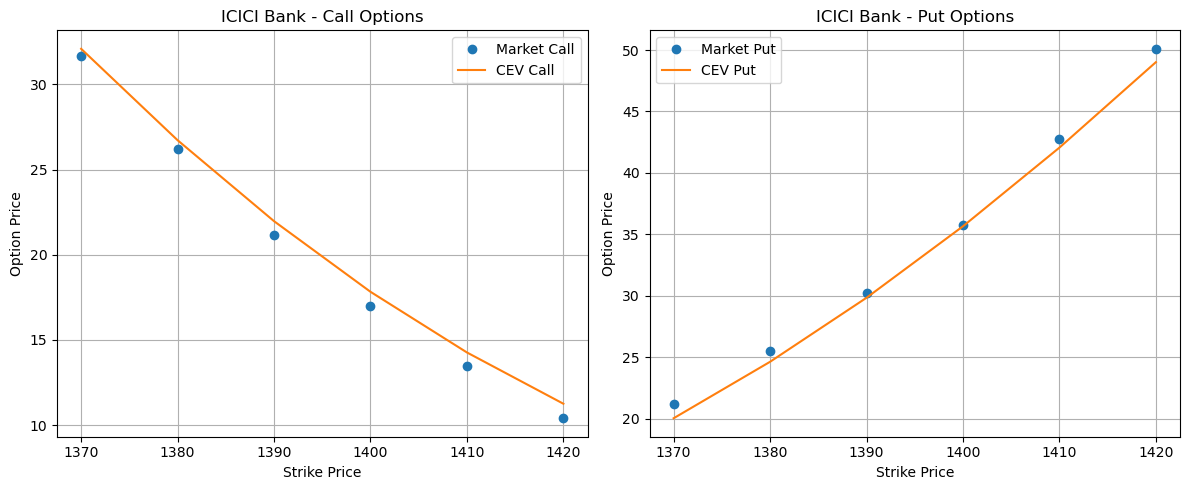

In [11]:
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)

plt.plot(
    df["Strike"], df["Call_Market"],
    "o", label="Market Call"
)

plt.plot(
    df["Strike"], df["CEV_Call"],
    "-", label="CEV Call"
)

plt.xlabel("Strike Price")
plt.ylabel("Option Price")
plt.title("ICICI Bank - Call Options")
plt.legend()
plt.grid(True)


plt.subplot(1, 2, 2)

plt.plot(
    df["Strike"], df["Put_Market"],
    "o", label="Market Put"
)

plt.plot(
    df["Strike"], df["CEV_Put"],
    "-", label="CEV Put"
)

plt.xlabel("Strike Price")
plt.ylabel("Option Price")
plt.title("ICICI Bank - Put Options")
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

# Evaluate model performance

In [12]:
call_mse = mean_squared_error(
    df["Call_Market"], df["CEV_Call"]
)

put_mse = mean_squared_error(
    df["Put_Market"], df["CEV_Put"]
)

print("Call MSE:", call_mse)
print("Put MSE:", put_mse)
print("Combined MSE:", result.fun)

Call MSE: 0.5351392825083848
Put MSE: 0.659160098131365
Combined MSE: 0.597149690319875
